# 01 · UJIIndoorLoc data audit

**Owner: Member 1 (Data and infrastructure lead).** This notebook describes training data and the official held-out validation file. It does not tune models on the held-out rows.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists(): ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from src.data.load import load_raw, prepare_data, WAP_COLUMNS
sns.set_theme(style="whitegrid")
train_raw, test_raw = load_raw(ROOT / "data/raw")
train, test, quality = prepare_data(train_raw, test_raw)
print(train_raw.shape, test_raw.shape, "→", train.shape, test.shape)
quality

(19937, 529) (1111, 529) → (19300, 474) (1111, 474)


{'train_rows_before': 19937,
 'train_duplicate_rows_removed': 637,
 'train_rows_after': 19300,
 'test_rows_unchanged': True,
 'test_rows': 1111,
 'never_detected_waps': ['WAP003',
  'WAP004',
  'WAP092',
  'WAP093',
  'WAP094',
  'WAP095',
  'WAP152',
  'WAP158',
  'WAP159',
  'WAP160',
  'WAP215',
  'WAP217',
  'WAP226',
  'WAP227',
  'WAP238',
  'WAP239',
  'WAP240',
  'WAP241',
  'WAP242',
  'WAP243',
  'WAP244',
  'WAP245',
  'WAP246',
  'WAP247',
  'WAP254',
  'WAP293',
  'WAP296',
  'WAP301',
  'WAP303',
  'WAP304',
  'WAP307',
  'WAP333',
  'WAP349',
  'WAP353',
  'WAP360',
  'WAP365',
  'WAP416',
  'WAP419',
  'WAP423',
  'WAP429',
  'WAP433',
  'WAP438',
  'WAP441',
  'WAP442',
  'WAP444',
  'WAP445',
  'WAP451',
  'WAP458',
  'WAP482',
  'WAP485',
  'WAP487',
  'WAP488',
  'WAP491',
  'WAP497',
  'WAP520'],
 'never_detected_wap_count': 55,
 'constant_waps_removed': ['WAP003',
  'WAP004',
  'WAP092',
  'WAP093',
  'WAP094',
  'WAP095',
  'WAP152',
  'WAP158',
  'WAP159',
  'WA

## Data quality

Duplicate rows are removed from training only. WAPs that are constant in the cleaned training data are removed from both frames. Readings in [-5, 0] dBm are flagged with their USERIDs and retained pending investigation.

In [2]:
quality_rows = pd.DataFrame([
    ["Duplicate training rows", quality["train_duplicate_rows_removed"], "Drop later copies"],
    ["Train-constant WAP columns", quality["constant_wap_count"], "Drop from both splits"],
    ["Observed readings in [-5, 0] dBm", quality["suspicious_near_zero_readings"], f"Flag only; USERIDs={quality["suspicious_users"]}"],
    ["Clean training scans", len(train), "Inner CV only"],
    ["Official test scans", len(test), "Final numbers only"],
], columns=["Issue", "Count", "Action"])
display(quality_rows)

,Issue,Count,Action
0,Duplicate training rows,637,Drop later copies
1,Train-constant WAP columns,55,Drop from both splits
2,"Observed readings in [-5, 0] dBm",224,"Flag only; USERIDs=[6, 14]"
3,Clean training scans,19300,Inner CV only
4,Official test scans,1111,Final numbers only


## Building and floor class balance

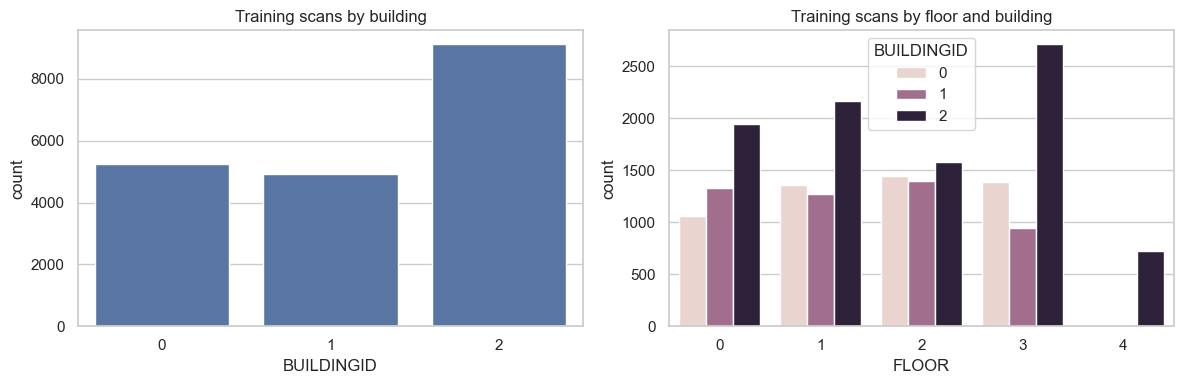

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=train, x="BUILDINGID", ax=axes[0]); axes[0].set_title("Training scans by building")
sns.countplot(data=train, x="FLOOR", hue="BUILDINGID", ax=axes[1]); axes[1].set_title("Training scans by floor and building")
plt.tight_layout()

## Detected access points and observed RSSI

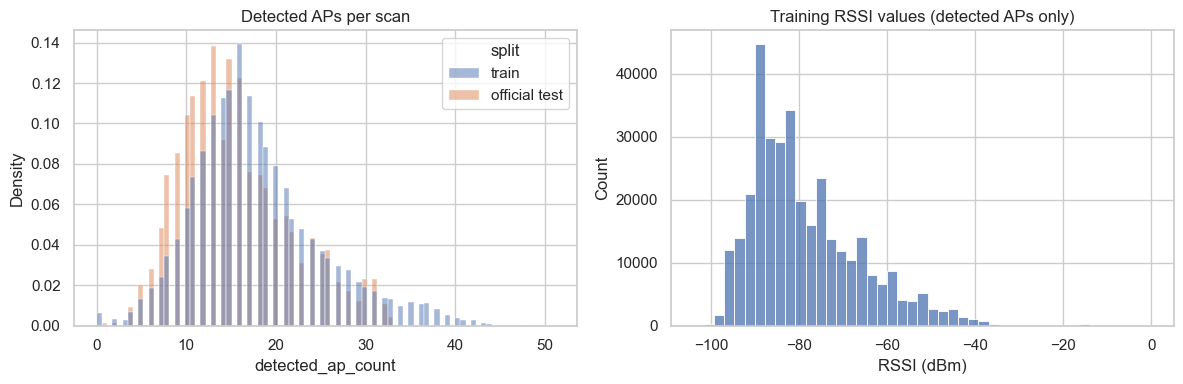

In [4]:
wap_cols = [c for c in WAP_COLUMNS if c in train.columns]
for name, frame in [("train", train), ("official test", test)]:
    frame["detected_ap_count"] = frame[wap_cols].ne(100).sum(axis=1)
    frame["mean_observed_rssi"] = frame[wap_cols].where(frame[wap_cols].ne(100)).mean(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=pd.concat([train.assign(split="train"), test.assign(split="official test")]), x="detected_ap_count", hue="split", stat="density", common_norm=False, ax=axes[0]); axes[0].set_title("Detected APs per scan")
observed = train[wap_cols].to_numpy(); observed = observed[observed != 100]
sns.histplot(observed, bins=45, ax=axes[1]); axes[1].set_title("Training RSSI values (detected APs only)"); axes[1].set_xlabel("RSSI (dBm)")
plt.tight_layout()

## Scans by user and phone

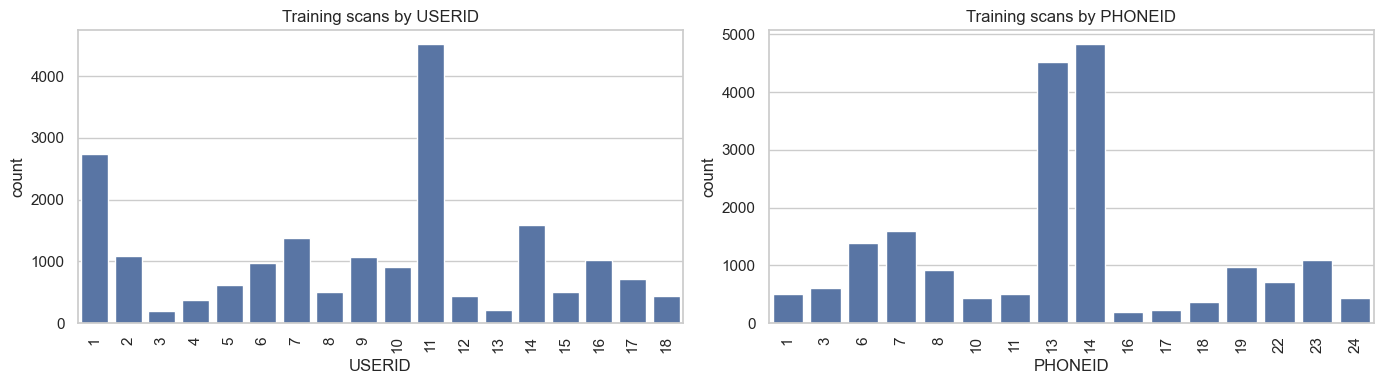

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=train, x="USERID", ax=axes[0]); axes[0].tick_params(axis="x", rotation=90); axes[0].set_title("Training scans by USERID")
sns.countplot(data=train, x="PHONEID", ax=axes[1]); axes[1].tick_params(axis="x", rotation=90); axes[1].set_title("Training scans by PHONEID")
plt.tight_layout()

## Coordinate maps

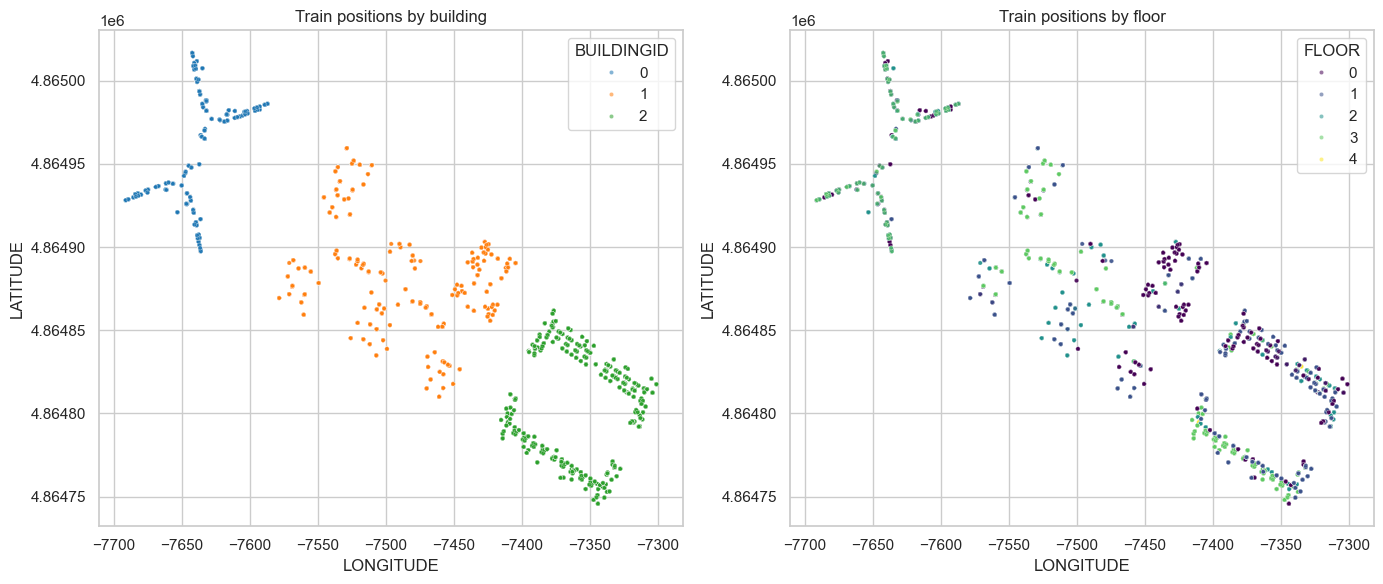

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(data=train, x="LONGITUDE", y="LATITUDE", hue="BUILDINGID", palette="tab10", s=9, alpha=.55, ax=axes[0]); axes[0].set_title("Train positions by building")
sns.scatterplot(data=train, x="LONGITUDE", y="LATITUDE", hue="FLOOR", palette="viridis", s=9, alpha=.55, ax=axes[1]); axes[1].set_title("Train positions by floor")
plt.tight_layout()

## Train vs official-test signal shift

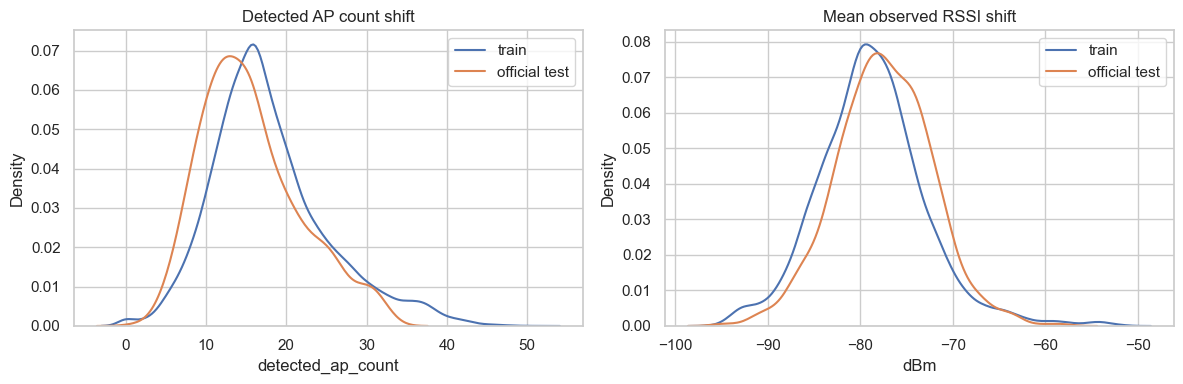

In [7]:
train_means = train[wap_cols].where(train[wap_cols].ne(100)).mean(axis=1)
test_means = test[wap_cols].where(test[wap_cols].ne(100)).mean(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(train["detected_ap_count"], label="train", ax=axes[0]); sns.kdeplot(test["detected_ap_count"], label="official test", ax=axes[0]); axes[0].legend(); axes[0].set_title("Detected AP count shift")
sns.kdeplot(train_means, label="train", ax=axes[1]); sns.kdeplot(test_means, label="official test", ax=axes[1]); axes[1].legend(); axes[1].set_title("Mean observed RSSI shift"); axes[1].set_xlabel("dBm")
plt.tight_layout()

## Split integrity

The persisted split file contains five GroupKFold partitions by USERID, plus the official held-out test designation. Each preprocessing object is fit inside the corresponding training fold.

In [8]:
from pathlib import Path
import json

artifact_dir = ROOT / "results"
figure_dir = artifact_dir / "figures"
table_dir = artifact_dir / "tables"
figure_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)
quality_rows.to_csv(table_dir / "data_quality.csv", index=False)

# Save numerical diagnostics alongside the report-ready plots.
user_summary = train.groupby("USERID").agg(
    scans=("USERID", "size"), distinct_phones=("PHONEID", "nunique"),
    buildings=("BUILDINGID", "nunique"), floors=("FLOOR", "nunique"),
).reset_index()
phone_summary = train.groupby("PHONEID").agg(
    scans=("PHONEID", "size"), distinct_users=("USERID", "nunique"),
    buildings=("BUILDINGID", "nunique"), floors=("FLOOR", "nunique"),
).reset_index()
user_summary.assign(entity="USERID").rename(columns={"USERID": "entity_id"}).to_csv(
    table_dir / "user_scan_summary.csv", index=False
)
phone_summary.assign(entity="PHONEID").rename(columns={"PHONEID": "entity_id"}).to_csv(
    table_dir / "phone_scan_summary.csv", index=False
)

shift_rows = []
for split_name, frame in (("train", train), ("official_test", test)):
    observed_values = frame[wap_cols].to_numpy()
    observed_values = observed_values[observed_values != 100]
    shift_rows.append({
        "split": split_name,
        "rows": len(frame),
        "detected_ap_mean": frame["detected_ap_count"].mean(),
        "detected_ap_std": frame["detected_ap_count"].std(),
        "detected_ap_median": frame["detected_ap_count"].median(),
        "mean_observed_rssi_dbm": float(np.mean(observed_values)),
        "observed_rssi_std_dbm": float(np.std(observed_values)),
    })
pd.DataFrame(shift_rows).to_csv(table_dir / "train_test_signal_shift.csv", index=False)

fold_payload = json.loads((ROOT / "data/splits/folds.json").read_text())
valid_seen = np.zeros(len(train), dtype=int)
integrity_rows = []
for fold in fold_payload["folds"]:
    tr_idx = np.asarray(fold["train_idx"], dtype=int)
    va_idx = np.asarray(fold["valid_idx"], dtype=int)
    valid_seen[va_idx] += 1
    overlap = set(train.iloc[tr_idx].USERID) & set(train.iloc[va_idx].USERID)
    integrity_rows.append({
        "fold": fold["fold"], "train_rows": len(tr_idx), "valid_rows": len(va_idx),
        "train_users": train.iloc[tr_idx].USERID.nunique(),
        "valid_users": train.iloc[va_idx].USERID.nunique(),
        "user_overlap_count": len(overlap),
        "valid_indices_unique": len(np.unique(va_idx)) == len(va_idx),
    })
assert np.all(valid_seen == 1), "Each training row must be validation exactly once"
assert all(r["user_overlap_count"] == 0 for r in integrity_rows), "USERID leakage between fold train/validation"
pd.DataFrame(integrity_rows).to_csv(table_dir / "split_integrity.csv", index=False)

# Standalone figures are convenient for the report and presentation.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=train, x="BUILDINGID", ax=axes[0]); axes[0].set_title("Training scans by building")
sns.countplot(data=train, x="FLOOR", hue="BUILDINGID", ax=axes[1]); axes[1].set_title("Training scans by floor and building")
fig.tight_layout(); fig.savefig(figure_dir / "eda_building_floor_balance.png", dpi=180, bbox_inches="tight"); plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=pd.concat([train.assign(split="train"), test.assign(split="official test")]), x="detected_ap_count", hue="split", stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Detected APs per scan")
train_observed = train[wap_cols].to_numpy(); train_observed = train_observed[train_observed != 100]
sns.histplot(train_observed, bins=45, ax=axes[1]); axes[1].set_title("Training RSSI values"); axes[1].set_xlabel("RSSI (dBm)")
fig.tight_layout(); fig.savefig(figure_dir / "eda_access_point_signal.png", dpi=180, bbox_inches="tight"); plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=train, x="USERID", ax=axes[0]); axes[0].tick_params(axis="x", rotation=90); axes[0].set_title("Scans by USERID")
sns.countplot(data=train, x="PHONEID", ax=axes[1]); axes[1].tick_params(axis="x", rotation=90); axes[1].set_title("Scans by PHONEID")
fig.tight_layout(); fig.savefig(figure_dir / "eda_user_phone_counts.png", dpi=180, bbox_inches="tight"); plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(data=train, x="LONGITUDE", y="LATITUDE", hue="BUILDINGID", palette="tab10", s=9, alpha=.55, ax=axes[0]); axes[0].set_title("Train positions by building")
sns.scatterplot(data=train, x="LONGITUDE", y="LATITUDE", hue="FLOOR", palette="viridis", s=9, alpha=.55, ax=axes[1]); axes[1].set_title("Train positions by floor")
fig.tight_layout(); fig.savefig(figure_dir / "eda_coordinate_maps.png", dpi=180, bbox_inches="tight"); plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(train["detected_ap_count"], label="train", ax=axes[0]); sns.kdeplot(test["detected_ap_count"], label="official test", ax=axes[0]); axes[0].legend(); axes[0].set_title("Detected AP count shift")
sns.kdeplot(train_means, label="train", ax=axes[1]); sns.kdeplot(test_means, label="official test", ax=axes[1]); axes[1].legend(); axes[1].set_title("Mean observed RSSI shift"); axes[1].set_xlabel("dBm")
fig.tight_layout(); fig.savefig(figure_dir / "eda_train_test_shift.png", dpi=180, bbox_inches="tight"); plt.close(fig)

print("Saved EDA tables, split integrity evidence, and figures under results/.")


Saved EDA tables, split integrity evidence, and figures under results/.
